# 01 · 项目介绍与环境搭建


## 资料来源与 14 天学习路线

本篇对应网盘 **day01 项目介绍&环境搭建**。先理解“谁用平台、课程怎样上线、学生怎样学习”，再准备开发环境并搭建父工程、基础工程。

| 本篇依据 | 定位与使用范围 |
|---|---|
| 《第1章 项目介绍&环境搭建v3.1.docx》 | 网盘 `day01/资料`；百度预览 39 页；完整读取项目背景、业务介绍、架构、环境、Git、基础工程 |
| 《学成在线项目开发环境配置v3.1.docx》 | 同目录；百度预览 21 页；完整读取正文、工具版本内嵌表格及配置截图 |
| `xuecheng-plus-project.zip` | `day01/代码`；核对 7 个 POM、模块目录及公共类，未执行课程代码 |
| [百度网盘分享](https://pan.baidu.com/s/16iXzw7cFDk3FqG9DfPqbdg?pwd=6633) | 提取码 `6633`；路径：Java 项目《学成在线》企业级开发实战 → 学成在线项目—资料 |
| [在线讲义入口](https://mx67xggunk5.feishu.cn/wiki/Y39iwM0mJidfeWkDmKJcp8uPn4f) | 网盘 `讲义在线地址.txt` 指向同一地址；正文以本次下载的 v3.1 原文件为准 |

网盘按 **14 天**组织，讲义按“章”组织，一章可能跨多天。以下编号跟随 day01—day14，不把讲义章数直接当作笔记篇数。

| 笔记 / 天 | 当天目录主题 |
|---|---|
| **01 / day01** | **项目介绍、环境搭建（本篇）** |
| 02 / day02 | 课程查询、新增课程、前后端联调 |
| 03 / day03 | 课程计划、JSR303 |
| 04 / day04 | 项目实战 |
| 05 / day05 | 媒资管理、Nacos、Gateway、MinIO |
| 06 / day06 | 断点续传、XXL-JOB |
| 07 / day07 | 视频处理、部署门户 |
| 08 / day08 | 课程发布、分布式事务 |
| 09 / day09 | 页面静态化、认证授权、Spring Security |
| 10 / day10 | JWT、用户认证、微信扫码登录 |
| 11 / day11 | 微服务授权、选课学习、支付接口测试 |
| 12 / day12 | 在线支付 |
| 13 / day13 | 在线学习、系统部署 |
| 14 / day14 | 项目优化、项目总结 |

> 阅读约定：课程事实按原资料记录；“补充 / 校正”用于解释原文容易混淆之处。图为讲义原图，已嵌入 Notebook，可离线阅读。命令是练习步骤，本篇编写时未安装或启动课程环境。


## 1. 项目背景：成人职业技能在线教育

理解业务背景，才能判断系统为什么需要机构入驻、课程审核和购买权限。

**学成在线**是面向成人职业技能教育的网络课堂平台，课程包括软件开发、职业资格、成人学历等。它属于**运营类应用软件**：平台持续组织课程供给、用户学习和交易，而非只给内部员工管理数据。

| 软件 / 研发类型 | 含义 | 例子 |
|---|---|---|
| 系统软件 | 为其他软件提供基础运行环境 | 操作系统 |
| 运营类应用 | 围绕商业模式持续服务客户 | 在线教育、外卖 |
| 管理类应用 | 管理组织内部数据与流程 | MIS 管理信息系统、ERP 企业资源计划 |
| 工具类应用 | 解决某个具体操作需求 | 文件处理、数据采集 |
| 自研 | 运营方自己的研发部门开发系统 | 课程设定中的学成在线 |
| 外包 | 运营方委托第三方软件公司研发 | 运营方为甲方，软件公司为乙方 |

讲义先介绍在线教育和 IT 培训市场：To C 面向消费者，To B 向机构提供课程内容、管理系统、直播服务等。SaaS 是直接使用软件服务，PaaS 是在服务平台上构建自己的应用。

**使用方式**：介绍本项目时说明成人教育定位、供给方和运营方式即可。讲义引用的是 2020—2021 年行业报告，图中的后续年份含预测；这些是课程背景，不能当作当前市场统计或自己所在公司的事实。


## 2. B2B2C：机构、平台与学生的关系

课程由机构提供、平台审核、学生消费，因此权限和流程必须区分三方。

**B2B2C**中的第一个 B 是培训机构，第二个 B 是平台运营方，C 是学生。平台连接供给和需求，并承担审核、展示、交易和学习服务。

| 模式 | 服务关系 | 教育场景 |
|---|---|---|
| B2B | 企业 → 企业 | 向培训机构提供教学管理系统 |
| B2C | 企业 → 消费者 | 一家机构直接向学生售课 |
| B2B2C | 机构 → 平台 → 学生 | 多机构入驻学成在线，学生在平台选课 |

`教学机构提供课程 → 平台审核与运营 → 学生选课并学习`

**怎么用**：设计课程接口时，既要识别当前登录者，还要识别其所属机构。两家机构都能编辑课程，并不表示 A 机构能修改 B 机构的课程。这种按机构隔离数据的规则，后续要在后端业务查询和更新条件中落实。


## 3. 三个业务端与核心角色

同一门课程在不同角色眼中有不同操作，不能只按页面名称理解系统。

| 业务端 | 使用者 | 主要职责 | 代表操作 |
|---|---|---|---|
| 用户端 | 学生 | 找课、购课、学习 | 搜索课程、选课、支付、查看学习记录 |
| 机构端 | 培训机构老师 | 组织和维护课程 | 编辑课程、上传图片视频、编排课程计划、提交审核 |
| 运营端 | 平台运营人员 | 审核与平台管理 | 审核课程 / 媒资、管理分类与用户 |

这里的“端”是按**业务角色**划分。架构图的 PC、APP、H5 是按**访问设备和界面形式**划分，两者不是同一维度。

例如，老师用 PC 浏览器进入机构端，学生既可能用 PC，也可能用 H5。课程里有三类业务端，不意味着必须实现三套独立后端。


## 4. 功能模块：从业务能力到服务边界

模块图用来理解平台全貌；当天先掌握核心模块的输入、输出和协作关系。

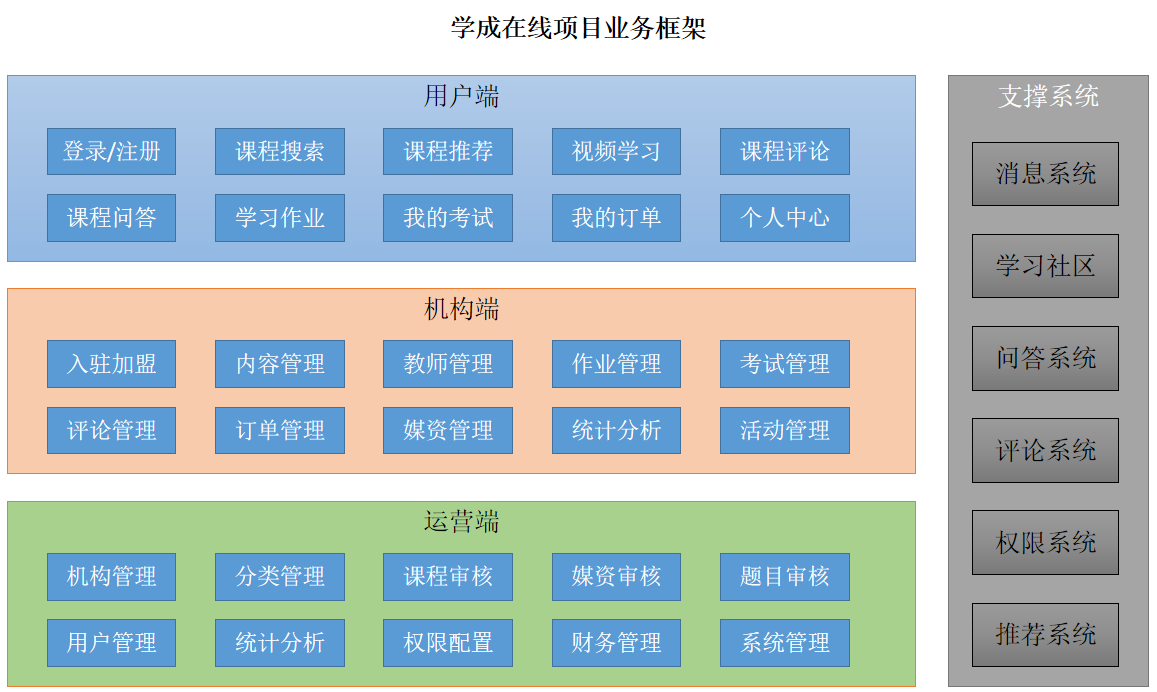

原图来源：《第1章》“项目业务介绍”。图中还展示评价、问答、考试、统计等扩展能力，不能据此认定 14 天课程已逐一实现。

| 核心模块 | 管理什么 | 与其他模块怎样协作 |
|---|---|---|
| 内容管理 | 基本信息、营销信息、课程计划、师资、审核与发布 | 关联媒资，发布后供搜索与学习使用 |
| 媒资管理 | 图片、视频等媒体资源及处理状态 | 将资源信息关联到课程计划 |
| 课程搜索 | 供用户检索的课程索引 | 消费已发布课程信息 |
| 订单支付 | 订单、支付过程与交易状态 | 支付完成后支持学习资格开通 |
| 选课 / 学习中心 | 学生的课程资格和学习记录 | 判断能否学习并记录学习过程 |
| 系统管理 | 分类、数据字典等公共业务配置 | 给内容管理等模块提供基础数据 |
| 认证授权 | 身份和访问权限 | 各服务校验调用者及操作权限 |

**怎么用**：先按业务责任划分模块，再判断是否需要独立部署。一个 Maven 子模块可以只是公共库；一个微服务也可以包含多个 Maven 子模块。


## 5. 课程编辑、审核与发布流程

老师保存课程信息之后，课程还不能直接供学生购买；需要审核和发布两个明确步骤。

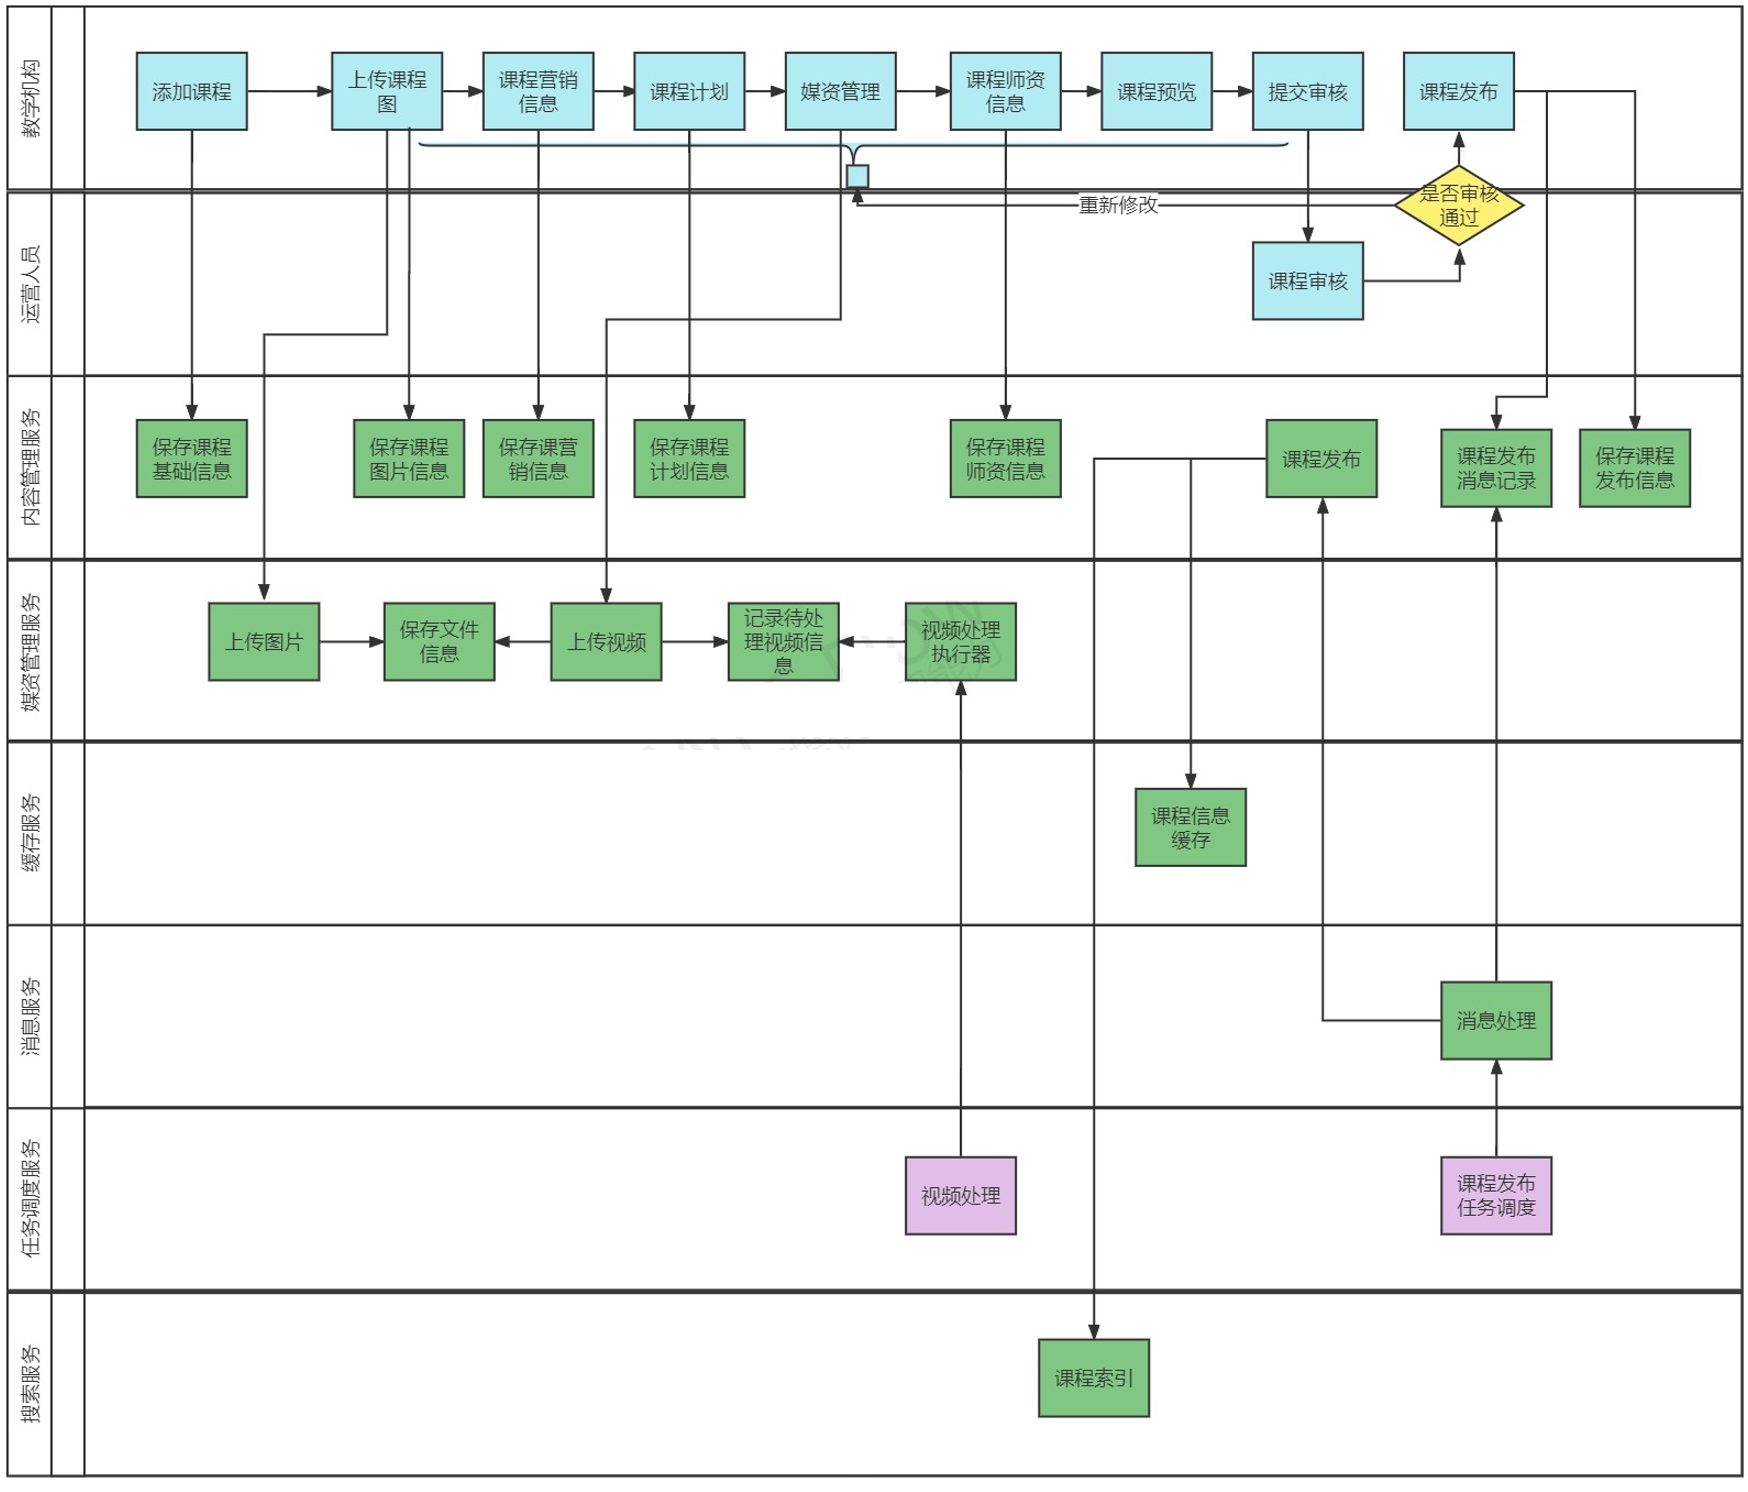

**泳道图**把步骤按执行者或服务分组，既能看顺序，也能看责任。原图来源：《第1章》“课程编辑与发布流程”。

| 阶段 | 操作与结果 |
|---|---|
| 编辑 | 添加课程基本信息，上传封面，设置营销信息 |
| 编排 | 创建课程计划，关联视频等媒资，填写师资 |
| 预览 | 检查学生看到的内容是否完整 |
| 提交审核 | 将课程交给运营方审核 |
| 审核 | 通过后进入可发布状态；不通过则返回修改 |
| 发布 | 保存课程发布信息，并触发搜索索引等更新 |

媒资上传和视频处理有自己的流程，课程管理只需要关联资源及其状态。课程发布则会影响数据库、搜索索引、缓存 / 静态资源，不能把多个系统的更新误当成一个数据库事务。

> 第一天只建立流程认识。“本地消息记录 + 任务调度”的发布可靠性方案在 day08 展开。最终一致性指相关系统允许短暂不同步，但通过重试等机制最终达到一致；它不是每一步同时成功。

**正例**：审核通过后由机构发起发布，系统记录发布信息并推进后续同步。  
**反例**：只保存草稿，就让课程进入面向学生的搜索结果。


## 6. 选课、支付与在线学习流程

“看到课程”“创建订单”“获得学习资格”是不同结果，混在一起会导致未付款就能学习。

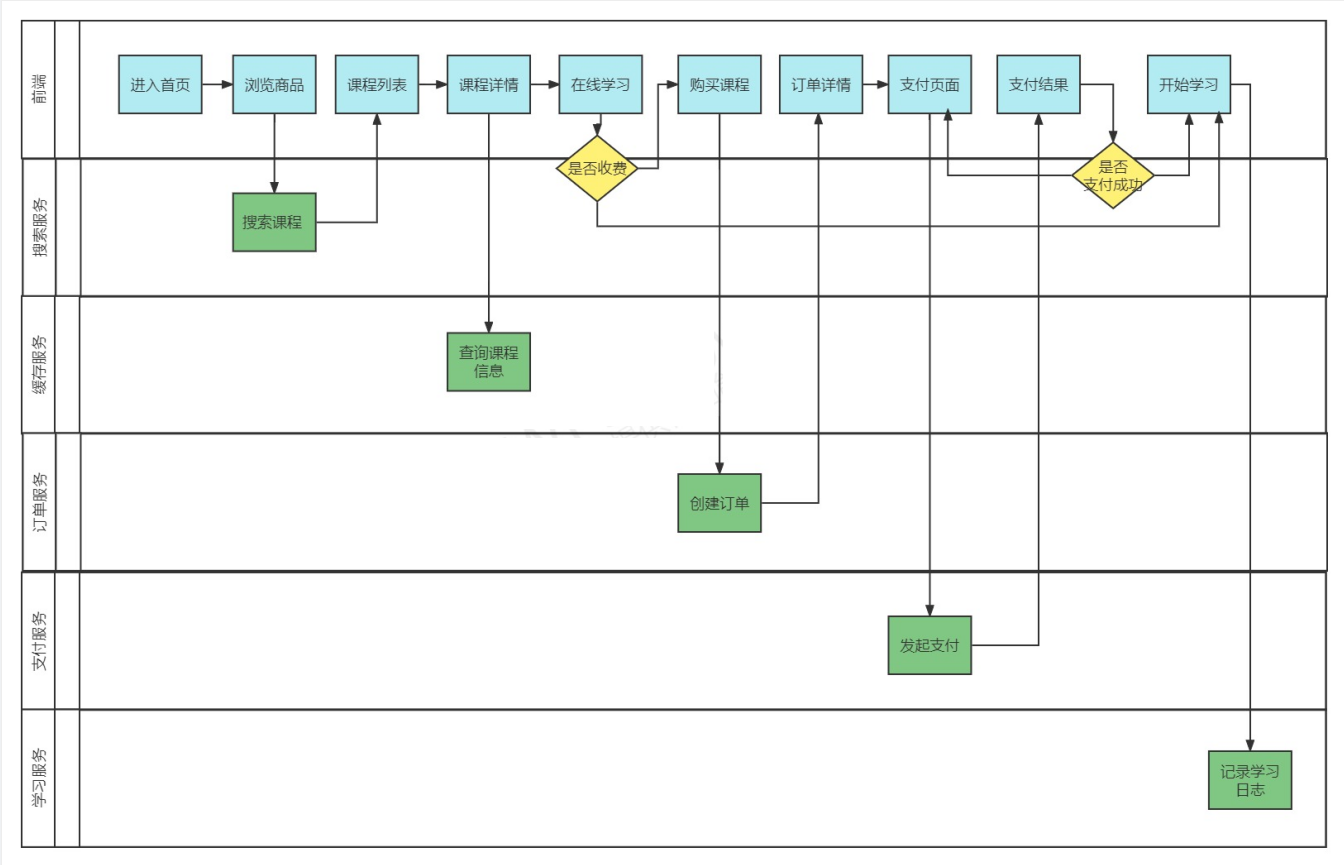

原图来源：《第1章》“学生选课流程”。

| 场景 | 主要路径 | 判断点 |
|---|---|---|
| 免费课程 | 搜索 / 浏览 → 详情 → 选课 → 学习 | 按课程规则取得免费学习资格 |
| 收费课程 | 详情 → 购买 → 创建订单 → 发起支付 → 支付成功 → 学习 | 后端确认支付状态并取得学习资格 |
| 支付未成功 | 留在未完成交易流程，按规则重试或结束 | 不能凭前端支付结果页面开放课程 |

开始学习后，学习服务记录学习过程。**认证**回答“你是谁”，**授权**回答“你是否有权学习这门课”；登录成功并不自动获得所有收费课程的权限。

**怎么用**：观察演示时，分别记录课程状态、订单状态、学习资格。免费课程练习重点是选课和学习入口；收费课程还需要确认支付与资格开通的衔接。


## 7. 技术架构：按层追踪一次请求

架构图的价值是解释一次访问经过哪些组件，以及每一层解决什么问题。

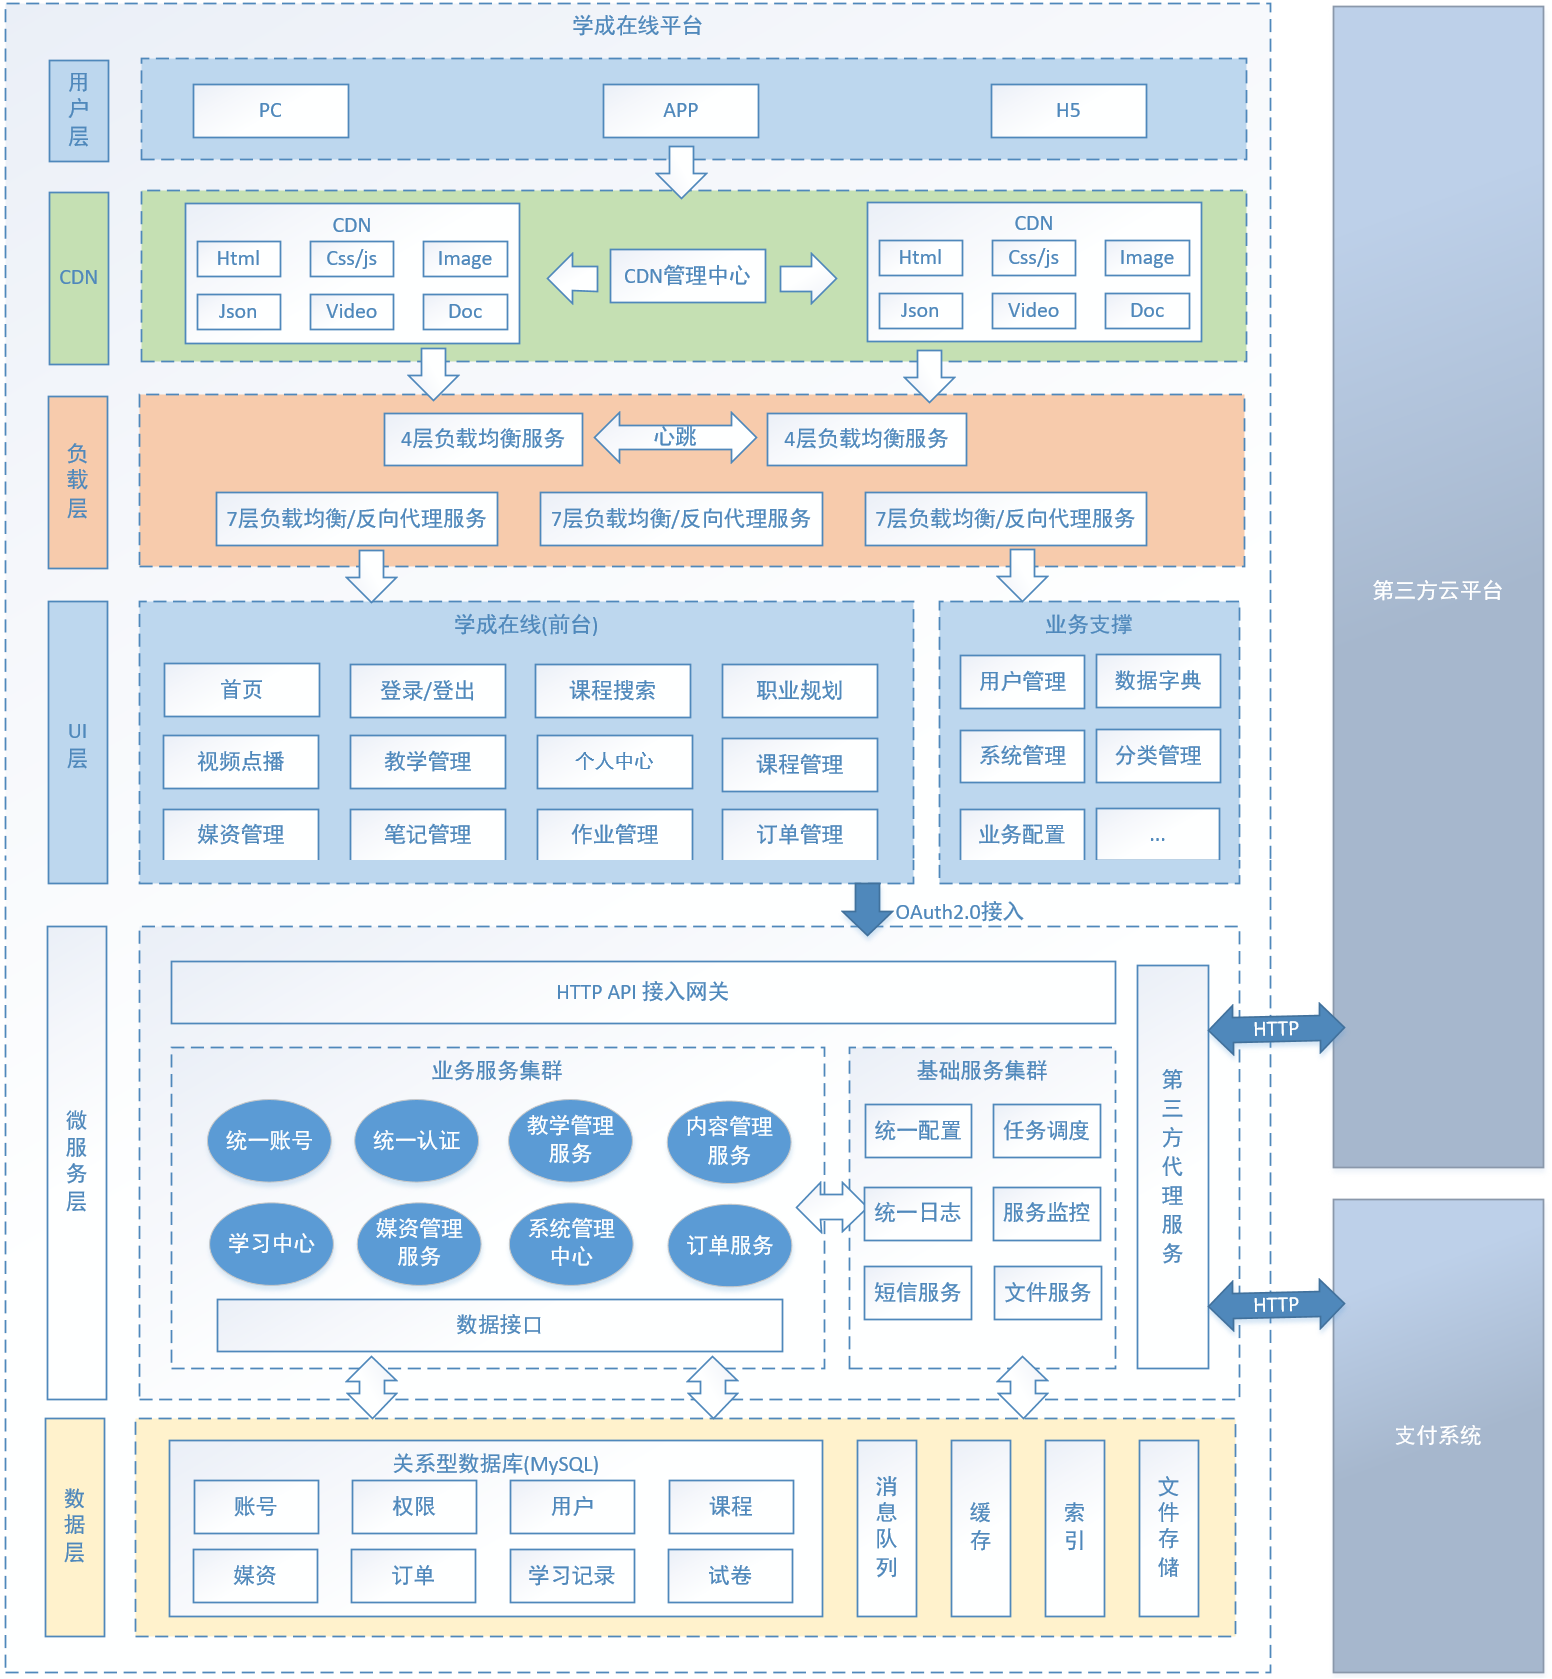

原图来源：《第1章》“项目技术架构”。这是整体架构示意，包含第三方接入和扩展能力；实际开发范围以当天代码和后续课程为准。

| 层次 | 职责 | 在本项目中的例子 |
|---|---|---|
| 用户层 | 表示访问设备 | PC、APP、H5 |
| CDN 层 | 就近分发静态资源 | HTML、JS、CSS、图片、文档、视频 |
| 负载均衡层 | 把访问分配到服务实例 | 四层转发、七层反向代理 |
| UI 层 | 展示页面并发起接口请求 | 门户、学习中心、教学管理 |
| 微服务层 | 执行业务、基础能力和第三方对接 | 内容管理、支付、认证、任务调度 |
| 数据层 | 按数据用途提供存储和查询 | MySQL、消息队列、缓存、索引库、文件存储 |

两条常见路径：

`加载课程封面 / 视频：用户 → CDN → 未命中时回源 → 文件存储`

`提交课程编辑：用户界面 → HTTP API 网关 → 内容管理服务 → MySQL`

**补充 / 校正**：图是组件关系图，不要求每次请求依次走完所有层。文件获取不必穿过内容管理服务；业务写请求也不能按静态文件的方式直接缓存。


## 8. 前后端分离与微服务

前端页面和后端业务有不同开发节奏，课程采用接口将它们连接起来。

**前后端分离**：前端负责界面和交互，后端通过 HTTP API 提供数据和业务操作；API 是双方约定的调用入口及请求 / 响应格式。后端使用 Spring Boot 构建应用，使用 Spring Cloud 相关组件支持分布式协作。

| 概念 | 解决的问题 | 不应混淆的点 |
|---|---|---|
| Spring Boot | 简化 Spring 应用配置和启动 | 采用 Boot 不代表已经是微服务 |
| 微服务 | 让不同业务服务可独立部署和演进 | 多个 Java 包不等于多个服务 |
| Spring Cloud | 为服务发现、配置、调用等提供组件体系 | 需要选择与 Boot 匹配的版本 |
| API 网关 | 统一外部入口，路由到相应服务 | 不负责替代各业务模块的核心逻辑 |

**怎么用**：先约定接口，再各自开发，最后联调。新增课程、课程查询等接口在 day02 实现；第一天的父工程和 base 工程都不是需要独立启动的业务服务。


## 9. CDN、四层与七层负载均衡

视频和静态文件适合就近分发，动态接口适合路由到合适的服务实例，这两种需求要分别处理。

**CDN**（内容分发网络）在多个节点缓存资源，减少用户访问源站的距离和压力。**源站**是提供原始资源的服务；**回源**是缓存未命中或需要更新时向源站获取资源。

| 机制 | 根据什么工作 | 典型用法 |
|---|---|---|
| CDN | 资源地址、缓存策略 | 加速封面、视频、静态 HTML 和文档 |
| 四层负载均衡 | 网络传输层的 IP、端口等信息 | 分发 TCP / UDP 流量 |
| 七层负载均衡 | 应用层的 HTTP Host、URL 路径等信息 | 按域名或路径分发请求 |
| 反向代理 | 代表后端接收客户端请求 | 将 `/api/` 转发至网关或服务 |

例如，`/video/a.mp4` 可以通过 CDN 获取，`/content/course` 可以按 HTTP 路径转发。HTTPS 场景若要按 HTTP 路径路由，需要在相应组件处解密处理请求。

> CDN 与文件存储职责不同：文件存储保存资源，CDN 分发资源。缓存命中时用户从边缘节点读取；不能因为 CDN 里有副本，就认定原始文件永久保存在 CDN。

讲义支持多层负载均衡，是否每层都部署应由实例数量、可用性和实际访问量决定。


## 10. 业务服务、基础服务和数据组件

服务划分要同时看业务责任和数据性质，不能把所有存储都当成 MySQL 的替代品。

| 服务类别 | 含义 | 例子 |
|---|---|---|
| 业务服务 | 执行核心业务规则 | 内容、媒资、搜索、订单支付、学习中心 |
| 基础服务 | 为系统运行提供通用能力 | 注册 / 配置中心、日志、任务调度 |
| 第三方代理服务 | 封装外部平台的对接 | 外部支付、短信、视频服务接入 |

**注册中心**记录可用服务实例，解决“服务在哪里”；**配置中心**集中管理配置，解决“服务用什么参数”。课程后续使用 Nacos 提供相关能力。

| 数据组件 | 适合保存 / 处理什么 | 课程中的用途 |
|---|---|---|
| MySQL | 有结构、需持久化的业务数据 | 课程、订单、学习记录 |
| Redis | 缓存等低延迟数据访问 | 减少热点查询压力 |
| RabbitMQ | 服务间待处理的消息 | 异步通知、解耦处理 |
| Elasticsearch | 适合搜索的索引数据 | 课程检索 |
| MinIO | 对象文件及其元数据 | 图片、视频、教学文档 |

**对象存储**用 bucket（存储桶）和 object key（对象标识）定位文件；**索引**是为检索组织的数据结构。MySQL 保存课程业务记录，Elasticsearch 保存用于搜索的课程信息，两份数据的用途不同。

**怎么用**：保存课程改 MySQL，上传视频走媒资 / 文件存储，搜索课程查索引。遇到同步延迟，先找数据如何传播，再判断是哪一份数据没更新。


## 11. 课程版本基线：先保持一套组合

环境相同但依赖版本不同，也可能造成无法编译或启动。复现课程先核对版本组合，再考虑迁移。

下表来自环境配置文档的**内嵌电子表格**，安装位置指课程安排：

| 软件 | 课程版本 | 位置 |
|---|---|---|
| IntelliJ IDEA | 2021.x 以上 | 个人电脑 |
| JDK | 1.8.x | 个人电脑 |
| Maven | 表格 3.8.x 以上；安装步骤指定 **3.8.6** | 个人电脑 |
| Git | 2.37.x；安装步骤使用 2.37.3 | 个人电脑 |
| VMware Workstation | 16.x | 个人电脑 |
| CentOS | 7.x | 虚拟机 |
| Docker | 18.09.0 | 虚拟机 |
| MySQL | 8.x | Docker |
| Nacos | 1.4.1 | Docker |
| RabbitMQ | 3.8.34 | Docker |
| Redis | 6.2.7 | Docker |
| XXL-JOB Admin | 2.3.1 | Docker |
| MinIO 服务端 | RELEASE.2022-09-07 | Docker |
| Elasticsearch / Kibana | 7.12.1 / 7.12.1 | Docker |
| Gogs | 0.13.0 | Docker |
| Nginx | 1.12.2 | Docker |

父 POM 与原讲义一致的核心版本：

| 依赖 | 版本 | 说明 |
|---|---|---|
| Spring Boot | **2.3.7.RELEASE** | 本项目的 Boot 基线 |
| Spring Cloud | **Hoxton.SR9** | 与课程 Boot 组合使用 |
| Spring Cloud Alibaba | **2.2.6.RELEASE** | 阿里组件依赖管理 |
| MySQL Connector/J | 8.0.30 | JDBC 客户端驱动，不是服务器版本 |
| MyBatis-Plus | 3.4.1 | ORM 辅助工具；ORM 将对象操作与关系数据操作关联 |
| MinIO Java SDK | 8.4.3 | 客户端库，不能当作 MinIO 服务端版本 |
| XXL-JOB Core | 2.3.1 | 应用内执行器客户端 |
| Elasticsearch 客户端 | 7.12.1 | 对应课程服务端基线 |

**补充 / 校正**：环境文档的 Maven 配置截图出现 3.6.1，文字安装步骤明确写 3.8.6；本篇按文字要求记录。课程使用 Java 8 和 `javax` 体系，不能直接替换成 Spring Boot 3 或 `jakarta` 后仍按原配置运行。以上是教学复现基线，不是新项目版本推荐。


## 12. 开发环境：本机与虚拟机怎样分工

开发者在本机写 Java，服务端中间件在虚拟机运行，两边需要通过网络互相访问。

`个人电脑：IDEA + JDK + Maven + Git + 数据库 / SSH 客户端`

`VMware → CentOS → Docker → MySQL、Nacos、Redis、RabbitMQ 等`

| 工具 | 职责 | 练习时怎样确认 |
|---|---|---|
| JDK | 编译、运行 Java | `java -version`、`javac -version` 均为课程 Java 8 |
| IDEA | 编辑、导入、调试工程 | Project SDK、模块 SDK、语言级别一致 |
| Maven | 解析依赖、构建工程 | `mvn -version` 显示期望 Maven、Java、Java home |
| Git | 记录代码版本 | `git --version`；IDEA 的 Git Test 成功 |
| DataGrip 等客户端 | 连接并查询数据库 | Test Connection 成功，可选择业务 schema |
| FinalShell 等 SSH 客户端 | 登录 Linux 执行管理命令 | 能连接自己的课程虚拟机 |

第一天最低完成要求是 **JDK、IDEA、Maven、Git、MySQL**。讲义允许虚拟机暂未搭好时先在本机准备 MySQL，保证 day02 可以访问数据库；后续用到其他服务时再完善虚拟机。

这些工具的安装、课程应用启动与业务接口验证是不同结果。只看到软件快捷方式，不能说明工程已具备正确环境。


## 13. IDEA：编码、SDK 与 Maven 运行环境

代码能输入，却因编码或编译器不同而失败，通常是配置没有在各处对齐。

| 设置 | 课程要求 / 用法 | 为什么 |
|---|---|---|
| 文件编码 | Global、Project、Properties 统一 UTF-8 | 避免中文乱码；截图另勾选 Properties 的透明 native-to-ascii 转换 |
| 自动导包 | 开启明确无歧义的自动导入、优化导入 | 多个同名类仍需手动选择正确包 |
| 代码补全大小写 | 按习惯关闭 Match case | 只影响提示，不改变 Java 大小写规则 |
| Project SDK | JDK 1.8 | 选择实际使用的开发工具包 |
| Language level | Java 8 | 限制源码使用的语法 |
| Maven Home | 指向课程 Maven 目录 | 统一构建工具 |
| User settings / Local repository | 指向实际 `settings.xml` 和本地仓库 | 与终端解析依赖保持一致 |

**怎么用**：在 Project Structure 检查 Project 和各 Module；在 Build Tools → Maven 检查安装目录及设置文件，并核对 Importer、Runner 使用的 JDK。

> IDE 本身运行的 Java，与项目编译和运行所用 JDK可以不同。IDEA 能启动，不代表 Maven 使用了 Java 8。

例如，源码语言级别已设 8，但 Maven 实际由另一套 JDK 运行，仍可能出现注解处理或依赖兼容问题。先看 `mvn -version`，不要只反复点击 Reload。


## 14. Maven 本地仓库、镜像与 settings.xml

工程依赖要从本地缓存或远端仓库取得，Maven 路径配置错误会导致下载重复、离线缺包或解析失败。

**本地仓库**保存已下载和 `install` 的构件；**远程仓库**提供依赖文件；**镜像**替代特定远程仓库的访问地址。

环境文档把文件名写为 `setting.xml`，正确文件名是 **`settings.xml`**。IDEA 应明确指向这份文件。下面是简化示例，路径需要按自己的电脑修改：

```xml
<?xml version="1.0" encoding="UTF-8"?>
<settings xmlns="http://maven.apache.org/SETTINGS/1.0.0"
          xmlns:xsi="http://www.w3.org/2001/XMLSchema-instance"
          xsi:schemaLocation="http://maven.apache.org/SETTINGS/1.0.0 https://maven.apache.org/xsd/settings-1.0.0.xsd">
  <localRepository>D:/maven/repository</localRepository>
  <mirrors>
    <mirror>
      <id>aliyun</id>
      <name>Aliyun public repository</name>
      <url>https://maven.aliyun.com/repository/public</url>
      <mirrorOf>central</mirrorOf>
    </mirror>
  </mirrors>
</settings>
```

原截图使用旧 HTTP 镜像地址，本示例校正为 HTTPS。`mirrorOf=central` 只替代 Maven Central，不等于拦截所有私服。

**怎么用**：可先将课程 `repository.zip` 解压到配置的本地仓库，再导入项目；压缩包不一定包含后续所有依赖，缺少构件时仍需正常解析。检查终端和 IDEA 的 Maven、settings 与 local repository 三项是否一致。

**正例**：用户配置、本地仓库路径和 IDEA Override 指向同一组文件。  
**反例**：IDEA 使用自带 Maven，终端使用另一个 Maven，还以为二者天然共享所有配置。


## 15. 虚拟机网络与课程服务启动

虚拟机模拟企业内网服务器。本机必须能访问虚拟机的 IP 和服务端口，Java 应用才能连接中间件。

| 项目 | 课程配置 |
|---|---|
| 虚拟机软件 | VMware Workstation 16.x |
| 系统 | CentOS 7 |
| VMnet8 网络 | NAT；子网 `192.168.101.0` |
| 子网掩码 | `255.255.255.0` |
| 课程虚拟机 IP | `192.168.101.65` |
| 资源建议 | 正文建议 8 GB 内存、4 核 CPU；截图显示 8 个处理器，以本机能力分配 |
| 登录工具 | FinalShell 等 SSH 客户端 |

**NAT**通过宿主机做地址转换，使虚拟机可访问外部网络；VMnet8 是 VMware 的对应虚拟网络。`192.168.101.0/24` 是网段，`.65` 才是这台课程虚拟机的主机地址。

资料提供两条路径：导入现成虚拟机，或自行安装系统。导入时解压课程文件，打开 `CentOS 7 64 位.vmx`，按讲义选择“已复制”，检查网络与硬件后启动。自行安装需另行准备软件和服务，不能假设具有同样的 `/data/soft/restart.sh`。

在**自己的课程虚拟机 SSH 会话**中，讲义使用：

```bash
systemctl start docker
sh /data/soft/restart.sh
docker ps
```

第一条启动 Docker 守护进程；第二条运行课程镜像内的服务脚本；第三条列出正在运行的容器。`docker ps -a` 可进一步看到已停止的容器。

课程镜像示例账号为 `root / centos`；它只属于发放的练习镜像，应以自己的环境为准。`192.168.101.65` 是内网教学地址，不能当成公共服务器。

> 顺序是“虚拟机开机 → 网络可达 → Docker 运行 → 容器运行 → 服务可连接”。容器出现在列表里，只说明进程在运行，还需用客户端确认对应服务可用。


## 16. MySQL：连接成功与业务库可用

day02 开始查询课程，第一天必须先准备可连接、包含课程数据的 MySQL 环境。

| 检查项 | 应确认什么 |
|---|---|
| 服务 | MySQL 容器已启动，或本机 MySQL 服务已启动 |
| 地址 | 虚拟机部署时使用实际虚拟机 IP；本机部署时使用本机地址 |
| 端口 | 使用 Docker 实际映射到宿主机的端口，课程示例为 3306 |
| 账号 | 使用自己课程环境中的数据库账号；SSH、Gogs、数据库账号分别管理 |
| 驱动 | 数据库客户端取得对应 MySQL 驱动 |
| Schema | 连接后选中业务数据库，避免只看到系统数据库 |
| 数据 | 数据库或初始化 SQL 与本套 `xuecheng-plus` 代码对应 |

数据库 **schema** 在 MySQL 场景通常可理解为数据库命名空间。可用以下只读 SQL 检查：

```sql
SELECT VERSION();
SHOW DATABASES;
```

当天资料同时有 `数据库`目录和`数据库.zip`；这里只确认了配套资料存在，未执行导入。课程代码包含 `xuecheng-plus-content`，应对照其连接配置及 SQL 判断所需业务库，不能拿旧版 `xc_` 数据库名称直接替换。

**怎么用**：在 DataGrip 的 Data Source 填入实际 Host、Port、User，执行 Test Connection，再选择业务 schema。若虚拟机未就绪，按讲义先准备本机 MySQL，并同步调整后续项目连接地址。


## 17. Git、Gogs 与仓库权限

团队需要保存版本并共享代码，Git 负责版本记录，Gogs 负责托管远程仓库和管理成员权限。

| 对象 | 职责 |
|---|---|
| Git | 本地提交、分支、合并和远程同步 |
| Gogs | 轻量 Git 托管平台 |
| 组织 | 将项目团队和仓库归在一起 |
| 团队 | 管理一组成员及相应权限 |
| 仓库 | 保存一个项目的版本历史 |
| 协作者权限 | 决定账号能读取、写入或管理仓库 |

环境文档流程是：创建组织 → 创建研发团队 → 创建成员账号 → 添加团队成员 → 创建仓库 → 配置协作者 → 上传初始代码 → 团队成员克隆。

课程 Gogs 示例入口为 `http://192.168.101.65:10880`，发放镜像的示例账号是 `gogs / gogs`。讲义与环境文档的组织、仓库名略有不同，**应从自己的 Gogs 仓库页面复制地址**。使用其他 Git 托管平台时也以实际地址和认证方式为准。

配置提交身份的课程示例：

```powershell
git config --global user.name "你的名字"
git config --global user.email "你的邮箱"
```

这两项写入提交作者信息，**不是远程登录密码**。学习练习也可使用仓库级 `git config user.name`、`git config user.email`，避免影响其他仓库。

**权限判断**：测试人员通常需要读取，开发人员需要读写；加入组织或团队后，还要核对目标仓库权限。认证通过，只能证明账号身份正确，不能证明拥有写入权限。


## 18. 克隆、提交与推送：代码处于哪一层

修改文件、记录版本、上传版本是三个动作，需要分别确认。

| 动作 | 变化发生在哪里 | 检查方式 |
|---|---|---|
| clone | 从远程复制仓库与历史到本地 | 本地有项目目录、`.git` 和远程配置 |
| add | 将选定修改放进暂存区 | `git diff --cached` |
| commit | 在本地创建一个提交 | `git log` |
| push | 把本地提交同步到远程 | 远程页面可见相应提交 |
| fetch | 获取远程最新引用与对象 | 不自动把它们合并进工作分支 |
| pull | 获取并按配置整合远程变化 | 操作前先确认当前分支和工作区 |

课程在 IDEA 选择从 Version Control 创建项目，输入真实仓库地址和本地路径。克隆后先检查：

```powershell
git remote -v
git status
git branch --show-current
```

完成父工程和 base 工程后，选择需要提交的文件，检查差异，再 commit 和 push。即使 IDEA 提供“Commit and Push”按钮，也要知道按钮执行了两步。

> 正例：本地提交后，在远程 `dev` 分支确认提交出现。反例：看到本地 commit 成功，就认为老师或其他成员已经能下载到修改。


## 19. dev 分支与每天作业分支

把练习放在可识别的分支，便于回退、对比和独立处理每天作业。

**分支**是指向提交的可移动引用。讲义使用 `dev` 做开发，并要求开始每天作业前创建新分支；不是每天创建一个全新仓库。

在刚克隆、确认工作区状态后：

```powershell
git switch -c dev
git push -u origin dev
git switch -c day01-environment
```

`-c` 创建并切换本地分支，`-u` 建立远程跟踪关系。若 `dev` 已存在，应切换现有分支，不要重复创建；若只有远程 `origin/dev`，可用 `git switch --track origin/dev`。`day01-environment` 是笔记示例名，课程只要求每日作业另建分支。

两种练习场景：

| 场景 | 操作原则 |
|---|---|
| 继续共同开发 | 基于正确的 `dev` 版本工作，提交后按团队规则整合 |
| 独立完成当日作业 | 从当前课程基线创建当天分支，完成后推送该分支并保留记录 |

**补充**：切分支前检查未提交修改；不要通过删除工作目录或强制覆盖来处理普通冲突。主分支名称可能是 `master` 或 `main`，应以仓库实际配置为准。


## 20. .gitignore 与 Git 故障定位

编译产物、IDE 本地配置会干扰协作，应让版本库主要保留源码与可共享配置。

课程提供较完整的 ignore 模板。核心规则可理解为：

```gitignore
target/
.idea/
*.iml
*.iws
*.ipr
.vscode/
logs/
```

源码、`pom.xml`、可共享的资源配置应保留；包含个人密码的本地配置不应直接提交。是否共享某个 IDE 配置，由团队约定决定。

**补充 / 校正**：`.gitignore`只控制未跟踪文件；已经提交过的文件，新增 ignore 规则不会让它自动退出历史。

| 现象 | 主要排查方向 |
|---|---|
| `Incorrect username or password (access token)` / HTTP 401 | 当前平台要求的账号、密码或 token；检查缓存的旧凭据 |
| HTTP 403 / Access denied | 目标仓库权限、协作者身份、分支限制 |
| 内网 Gogs 无法访问 | IP、10880 端口、虚拟机网络、容器状态 |
| 本地提交有，远程看不到 | 是否 push、目标远程、目标分支是否正确 |

讲义展示了 Windows 凭据管理器和 IDEA 密码保存设置。处理认证问题时要定位**对应托管平台**的记录；不要把改变提交邮箱当作登录修复。密码变更属于账号管理动作，笔记中的定位步骤不代表已经修改过任何凭据。


## 21. Maven：继承、依赖与聚合是三种关系

这三种关系混淆后，会出现“依赖了 base 却没有版本管理”或“父工程有了却没有一起构建”等问题。

| 关系 | POM 写在哪里 | 作用 |
|---|---|---|
| 继承 | 子项目的 `<parent>` | 继承父 POM 的属性、依赖管理和可继承构建配置 |
| 依赖 | 使用方的 `<dependencies>` | 把构件及可传递依赖加入所需 classpath |
| 聚合 | 聚合项目的 `<modules>` | 一次构建多个模块，Maven 按依赖关系排序 |
| 版本管理 | 父 POM / BOM 的 `<dependencyManagement>` | 统一默认版本和 scope 等信息，本身不引入依赖 |

**POM**是 Maven 的项目模型文件 `pom.xml`；**构件**通常是按坐标发布的 JAR 或 POM。**classpath**是编译器或运行时寻找类的路径集合。

课程讲义给出“parent → base → 微服务”的简图，需按 POM 细分：

```text
继承关系（读取 parent）
xuecheng-plus-base ─────────────→ xuecheng-plus-parent
xuecheng-plus-content ──────────→ xuecheng-plus-parent
content-api / model / service ──→ xuecheng-plus-content

依赖关系（读取 dependencies）
content-api → content-service → content-model → xuecheng-plus-base

聚合关系（读取 modules）
xuecheng-plus-content
  ├─ xuecheng-plus-content-api
  ├─ xuecheng-plus-content-model
  └─ xuecheng-plus-content-service
```

> **校正原文**：“依赖 base，间接继承 parent”不能作为 Maven 规则。依赖的 POM 不会成为自己的父 POM；实际代码通过 content 的 parent 链继承版本管理，通过 dependencies 链使用 base 公共库。

**正例**：model 的 parent 链来自 content / parent，同时显式依赖 base。  
**反例**：一个独立项目只添加 base 依赖，就认为自动拥有 parent 的编译插件配置。

两种用途也要分清：统一版本用继承；统一构建用聚合。一个项目可以同时承担父 POM 和聚合职责，但 **`packaging=pom` 本身不会自动聚合任何目录**。


## 22. 父工程：坐标、BOM 和版本管理

多个服务各自填写依赖版本，容易出现冲突。父工程集中定义一套版本与构建基线。

课程父工程坐标：

| 字段 | 值 | 含义 |
|---|---|---|
| groupId | `com.xuecheng` | 构件所属组织 / 分组 |
| artifactId | `xuecheng-plus-parent` | 构件名称 |
| version | `0.0.1-SNAPSHOT` | 开发中的快照版本 |
| packaging | `pom` | 发布项目模型，不作为普通代码 JAR |

创建父工程时可以建普通 Maven 模块，编写 POM。讲义使用 Spring Initializr 后清理生成文件；如今生成器提供的版本与课程可能不同，手工按原 POM 创建即可，不必为无业务代码的父工程保留启动类。

父 POM 的核心结构摘录如下；实际练习应使用课程完整 POM，以下只展示版本管理关系：

```xml
<?xml version="1.0" encoding="UTF-8"?>
<project xmlns="http://maven.apache.org/POM/4.0.0">
  <modelVersion>4.0.0</modelVersion>
  <groupId>com.xuecheng</groupId>
  <artifactId>xuecheng-plus-parent</artifactId>
  <version>0.0.1-SNAPSHOT</version>
  <packaging>pom</packaging>
  <properties>
    <java.version>1.8</java.version>
    <project.build.sourceEncoding>UTF-8</project.build.sourceEncoding>
    <spring-boot.version>2.3.7.RELEASE</spring-boot.version>
    <spring-cloud.version>Hoxton.SR9</spring-cloud.version>
    <spring-cloud-alibaba.version>2.2.6.RELEASE</spring-cloud-alibaba.version>
  </properties>
  <dependencyManagement>
    <dependencies>
      <dependency>
        <groupId>org.springframework.cloud</groupId>
        <artifactId>spring-cloud-dependencies</artifactId>
        <version>${spring-cloud.version}</version>
        <type>pom</type>
        <scope>import</scope>
      </dependency>
      <dependency>
        <groupId>org.springframework.boot</groupId>
        <artifactId>spring-boot-dependencies</artifactId>
        <version>${spring-boot.version}</version>
        <type>pom</type>
        <scope>import</scope>
      </dependency>
      <dependency>
        <groupId>com.alibaba.cloud</groupId>
        <artifactId>spring-cloud-alibaba-dependencies</artifactId>
        <version>${spring-cloud-alibaba.version}</version>
        <type>pom</type>
        <scope>import</scope>
      </dependency>
    </dependencies>
  </dependencyManagement>
</project>
```

**BOM**（Bill of Materials）是统一一批依赖版本的 POM。`type=pom`、`scope=import`在`dependencyManagement`中引入 BOM；它不会把这批库全部下载并加入应用。

**怎么用**：父 POM 管好版本，业务子模块在`dependencies`中按需声明库。被父 POM 管理的依赖可省略版本；本地显式指定其他版本会改变解析结果，因此排错时要看 effective POM 和依赖树。


## 23. 父 POM 的库版本与构建配置

除了三套 BOM，课程对一批库显式管理版本，并设置 Java 8 编译和资源处理。

| 库 / 插件 | 原 POM 版本 | 用途 |
|---|---|---|
| Lombok | 1.18.8 | 编译期生成常见 Java 样板代码 |
| MapStruct | 1.3.1.Final | 编译期生成 Java Bean 映射代码 |
| Servlet API | 4.0.1 | Web 容器接口；原 POM 为 provided |
| Fastjson | 1.2.83 | JSON 转换 |
| Druid Starter | 1.2.8 | 数据库连接池 |
| Commons Lang / Lang3 | 2.6 / 3.10 | 两代工具库，包名不同 |
| Guava | 25.0-jre | 通用工具库 |
| Swagger Annotations | 1.5.20 | 接口文档注解 |
| Swagger Spring Boot Starter | 1.9.0.RELEASE | 课程接口文档集成 |
| OkHttp | 4.8.1 | HTTP 客户端 |
| Maven Compiler Plugin | 3.8.1 | 编译 Java、执行注解处理 |
| Maven Resources Plugin | 3.3.0 | 复制和过滤资源文件 |

MySQL、MyBatis-Plus、MinIO、XXL-JOB、Elasticsearch 的显式版本见第 11 节；MyBatis-Plus Generator 同为 3.4.1，Boot Test Starter 同为 2.3.7.RELEASE，并排除 `junit-vintage-engine`。

| 构建项 | 原配置 | 理解与使用 |
|---|---|---|
| 编译级别 | `source=1.8`、`target=1.8` | 源码语法与生成 class 目标版本；仍需核对真实 JDK |
| 注解处理 | `annotationProcessorPaths`列出 Lombok | 编译期运行代码生成器 |
| 输出名称 | `finalName=${project.name}` | 使用 project name 决定构建产物名称 |
| 主资源 | `src/main/resources`，`filtering=true`，包含`**/*` | 复制资源，并替换匹配的占位符 |
| Java 目录内资源 | `src/main/java`包含`**/*.xml` | 把放在 Java 目录下的 Mapper XML 等复制到输出目录 |
| 资源编码 | UTF-8 | 保持文本配置编码一致 |

**注解处理器**在编译阶段生成或修改编译内容。原 POM 管理了 MapStruct 库和处理器，但`annotationProcessorPaths`只列 Lombok；后续若使用 MapStruct，应检查处理器是否真正参与编译。

> 导入 `spring-boot-dependencies`只继承依赖版本管理，不等于继承`spring-boot-starter-parent`的插件配置。原父 POM 显式设置编译和资源插件，就是需要关注的构建部分。

**补充 / 校正**：如果以后把图片、视频等二进制文件放进工程资源，应单独排除文本过滤；不要把所有文件无差别做占位符替换。当前原 POM 没有`modules`，它提供父 POM 职责，不能直接从该目录一键构建全部兄弟模块。


## 24. 基础工程 base：公共库、parent 与 relativePath

分页模型、日期序列化等会被多个服务复用，应放到基础库，避免每个服务复制一份。

**`xuecheng-plus-base`**继承`xuecheng-plus-parent`，默认打包为 JAR，提供公共模型、配置和工具能力。它不是业务微服务。

下面是关系清晰的简化 POM；课程完整 base POM 还声明了表中其他库：

```xml
<?xml version="1.0" encoding="UTF-8"?>
<project xmlns="http://maven.apache.org/POM/4.0.0">
  <modelVersion>4.0.0</modelVersion>
  <parent>
    <groupId>com.xuecheng</groupId>
    <artifactId>xuecheng-plus-parent</artifactId>
    <version>0.0.1-SNAPSHOT</version>
    <relativePath>../xuecheng-plus-parent/pom.xml</relativePath>
  </parent>
  <artifactId>xuecheng-plus-base</artifactId>
  <dependencies>
    <dependency>
      <groupId>org.projectlombok</groupId>
      <artifactId>lombok</artifactId>
    </dependency>
    <dependency>
      <groupId>org.apache.commons</groupId>
      <artifactId>commons-lang3</artifactId>
    </dependency>
  </dependencies>
</project>
```

`relativePath`用于定位父 POM，不是依赖 JAR 的位置。原资料写`../xuecheng-plus-parent`，本例明确到`pom.xml`；两者在对应目录结构中指向同一父模型。若省略，Maven 默认尝试`../pom.xml`；写空`<relativePath/>`则不从该相对文件位置解析父模型。

| base 的能力组 | 原 POM 中的库 |
|---|---|
| 简化代码 / 接口描述 | Lombok、Swagger Annotations |
| 通用工具 / 编解码 | Commons Lang、Lang3、Commons Codec 1.11 |
| JSON 与 Java 类型支持 | Fastjson；Jackson parameter-names、jdk8、jsr310 模块 |
| Web 与校验 | Servlet API provided、Spring Web、Boot Validation |
| 日志 | Boot Log4j2 Starter |
| 文件类型判断 | simplemagic 1.17，用于识别 MIME 类型 |
| 二维码 | ZXing core / javase 3.3.3 |

**MIME 类型**表示文件内容格式，例如`image/png`。**JSR310**对应 Java 8 日期时间 API，如`LocalDateTime`；JSR303 / Bean Validation 是参数校验规范，两者不同。

> 原 base POM 重复声明了`commons-lang3`，实际整理时保留一项即可。依赖公共库可能传递引入一组其他库，因此 base 应保持稳定，避免塞入只给单个业务模块使用的大量能力。

当天讲义说公共类“待需要时开发”；代码包已含`PageParams`、`PageResult`、`LocalDateTimeConfig`。第一天知道它们分别服务于分页输入、分页结果和日期 JSON 转换即可，具体用法随 day02 展开。


## 25. 目录结构与配套代码的范围差异

代码压缩包比第一章的课堂目标更靠后，照着全部文件实现会把第二天业务混入第一天。

第一章完成后的最小结构：

```text
xuecheng-plus-project/
├─ .gitignore
├─ xuecheng-plus-parent/
│  └─ pom.xml                    # 版本与构建管理，packaging=pom
└─ xuecheng-plus-base/
   ├─ pom.xml                    # 继承 parent，默认 JAR
   └─ src/main/java/             # 公共类按需求添加
```

下载的 day01 代码包另含：

| 路径 | 实际内容 | 本篇处理 |
|---|---|---|
| `xuecheng-plus-content` | 聚合 content-api / model / service | 只核对继承、聚合和依赖关系 |
| `content-api` | 启动类、课程查询 Controller、bootstrap.yml、Log4j2 配置 | day02 学习具体接口与联调 |
| `content-model` | 课程查询 DTO、课程等 PO | day02 展开模型与数据库映射 |
| `content-service` | 依赖 model 的业务模块骨架 | 随业务实现补充 |
| `xuecheng-plus-generator` | 代码生成器与模板、生成样例 | 暂不运行 |

**DTO**是传输数据的对象，例如查询条件；**PO**是与持久化数据对应的对象。它们属于后续业务接口和数据库设计内容。

**补充 / 校正**：压缩包根目录没有根`pom.xml`，parent 的 POM 也没有`modules`；content 才列出三个子模块。IDEA 能显示多个模块，不等于 Maven 已有根聚合工程。

**怎么用**：从零练习先建 parent 与 base；阅读配套代码可作为结构核对。需要命令行构建时，要在具有 POM 的目录执行或用`-f`明确指定，不能默认在压缩包根目录执行就能构建全部工程。


## 26. 构建排错：看有效模型与依赖树

依赖飘红并不总是下载失败，父 POM 地址、版本、仓库配置和构建范围都可能影响结果。

下列命令是练习时的诊断示例，**编写本笔记时未执行 Maven 构建**：

```powershell
mvn -version
mvn -f xuecheng-plus-base/pom.xml help:effective-pom
mvn -f xuecheng-plus-base/pom.xml dependency:tree
```

**effective POM**是合并继承、属性和依赖管理后的有效模型；**依赖树**展示直接与传递依赖，帮助找到实际引入路径。没有聚合构建时，可先在自己的练习工程中将 parent`install`到本地仓库，再构建 base；若父模型已能由相对路径解析，是否需要安装取决于后续构建与消费方式。

| 现象 | 优先检查 |
|---|---|
| `Non-resolvable parent POM` | parent 坐标、relativePath、父文件是否存在；本地 / 远程仓库是否有对应 POM |
| 某依赖没有版本 | 是否位于正确 parent 链；是否真的在依赖管理中；groupId / artifactId 是否拼错 |
| `Could not find artifact` | 版本是否存在、仓库配置、网络；内部模块是否未在本次构建或本地仓库中 |
| Java 版本错误 | `mvn -version`、IDEA Runner / Importer JDK、编译级别 |
| Lombok 方法不存在 | 注解处理器配置及实际编译方式 |
| Mapper XML 找不到 | XML 所在目录、resources 配置、输出目录内是否真的包含文件 |
| 日志实现冲突 | 依赖树是否同时引入默认日志与 Log4j2 |

课程 content-api POM 有排除`spring-boot-starter-logging`的配置。排除作用于对应依赖路径，不能凭一处 exclusion 就推断所有路径都已消除，应看最终依赖树。

两类常见场景：父模型解析失败先查坐标与路径；运行时重复类或日志绑定先查依赖树。二者都不应直接靠随机改版本解决。


## 27. 第一天验收与资料对应清单

第一天的产出是可继续开发的环境和基础工程，验收应落在可观察结果上。

| 验收目标 | 自己练习时应保留的证据 |
|---|---|
| 业务理解 | 能说清三方角色、审核发布、免费 / 收费选课路径 |
| 架构理解 | 能解释 MySQL、索引、缓存、文件存储及网关各自用途 |
| Java 环境 | 终端与 IDEA 的项目 JDK、Maven JDK 对齐到 Java 8 |
| Maven 环境 | 实际 Maven / settings / local repository 路径已核对 |
| 数据库 | Test Connection 成功，业务 schema 和课程数据可用 |
| Git 环境 | Git 可用，实际仓库地址和权限正确 |
| 分支 | dev 与当天作业分支按课程要求建立 |
| 基础工程 | parent 为 POM，base parent 坐标与路径正确，依赖解析正常 |
| 版本记录 | 已检查提交差异，推送后远程能看到对应提交 |

原资料覆盖定位：

| 原材料章节 | 本篇位置 |
|---|---|
| 第一章：在线教育、IT 培训、项目背景 | 1—2 |
| 第一章：业务模块、发布 / 学习流程、技术架构 | 3—10 |
| 第一章：环境与 Git | 11—12、17—20 |
| 第一章：工程关系、父工程、基础工程 | 21—25 |
| 环境文档：版本、IDEA、Maven | 11—14 |
| 环境文档：虚拟机、数据库 | 15—16 |
| 环境文档：Git、Gogs 组织 / 团队 / 仓库 | 17—20 |
| 第一章：面试表达 | 28 |

当天资料中的第二章讲义、前端工程、SQL、日期配置、日志配置、生成器，是后续实践配套；本篇未把它们当成已经完成的接口实现。

**本笔记的验证范围**：已完整提取两份 DOCX 正文，读取工具版本内嵌表格，查看关键原图，静态核对配套代码的 POM。Notebook 结构、图片附件、示例 XML 和版本一致性通过静态检查；未安装环境、导入数据库、运行课程脚本、启动应用或验证业务接口。上表是读者的验收目标，不是已完成实验记录。


## 28. 面试：把项目讲清楚

介绍项目应从业务到技术，再到自己实际做过的部分，而不是先背中间件名单。

| 顺序 | 要回答的问题 |
|---|---|
| 背景 | 什么平台，面向谁，供给方和运营方是谁 |
| 流程 | 课程如何编辑、审核、发布；用户如何选课、付费、学习 |
| 模块 | 内容、媒资、搜索、订单支付、学习中心各自负责什么 |
| 架构 | 前后端如何连接；业务数据、索引、文件怎样分工 |
| 职责 | 自己实际负责或练习过哪个模块 |
| 方案 | 用具体实现说明设计、取舍与验证结果 |

学习项目可以这样介绍：

> 我学习并实践的是黑马学成在线课程项目，一个采用 B2B2C 模式的成人职业技能教育平台。教学机构编辑课程并提交审核，平台运营人员审核后允许发布；学生对免费课程直接选课学习，对收费课程需要完成支付并取得学习资格。项目采用前后端分离，后端基于 Spring Boot 和 Spring Cloud，按内容、媒资、搜索、订单支付、学习中心等业务划分服务。当前第一天完成的是项目理解与基础工程准备，具体业务实现随课程推进。

将最后一句按**自己真实进度**修改。原讲义中的“公司自研”“我负责内容、媒资、支付”等是示例口径，不能直接当作自己的工作经历。

**面试提示**：高频追问是 B2B2C 与三端职责、审核和发布的区别、免费与收费学习权限、CDN 与文件存储的区别，以及 Maven 继承 / 依赖 / 聚合。回答 Maven 时给出实际 POM 链：base 与 content 继承 parent，content 的子模块继承 content，model 依赖 base；`dependencyManagement`管版本，`dependencies`引库，`modules`组织构建。
